# CC3045 – Deep Learning · Laboratorio 9
**β-VAE, difusión DDPM condicional y pass@k — PyTorch desde cero**

Notebook autocontenido inspirado en la organización del Lab 8: teoría breve → implementación → visualización → análisis sustentado en resultados. Ejecute en orden. **Los resultados no están precalculados**: las tablas y respuestas experimentales se obtienen ejecutando las celdas. El entrenamiento de difusión y su muestreo completo requieren preferiblemente GPU.

**Restricciones:** sin `diffusers`, `torch.distributions.kl_divergence` ni calendarios/muestreadores prefabricados. Semilla: **42**. Los prompts utilizados para la asistencia y su justificación se documentan al final; revise la política de uso de IA del curso.

## Preparación · Librerías, reproducibilidad y dispositivo

In [7]:
import os, math, time, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
OUT = Path('lab9_outputs'); OUT.mkdir(exist_ok=True)
# Para probar conexiones rápidamente; en la entrega usar FAST_DEV_RUN=False.
FAST_DEV_RUN = False
NUM_WORKERS = 0  # compatible con Windows/Jupyter
print('Semilla:', SEED, '| Dispositivo:', device, '| PyTorch:', torch.__version__)

Semilla: 42 | Dispositivo: cpu | PyTorch: 2.14.1+cpu


## Task 1 — Autoencoder variacional (entrega parcial)
### Task 1.1 — Preparación de Fashion-MNIST
Se normalizan los píxeles a [0,1] y se reservan los últimos 5,000 ejemplos para validación. Mantener esta partición permite comparar los tres valores de β sobre las mismas imágenes.

In [8]:

batch_size = 128
latent_dim = 2
epochs_vae = 20
lr_vae = 1e-3
beta_values = [0.1, 1.0, 10.0]

# Fuente alternativa de Fashion-MNIST para evitar el error HTTP 403 del servidor predeterminado.
datasets.FashionMNIST.mirrors = [
    "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
]

# ToTensor convierte los valores de los píxeles al intervalo [0, 1].
raw_train = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=transforms.ToTensor()
)

test_set = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

# Se conserva el orden original: 55,000 imágenes para entrenar y las últimas 5,000 para validar.
train_set = Subset(raw_train, range(55000))
val_set = Subset(raw_train, range(55000, 60000))

train_loader = DataLoader(
    train_set,
    batch_size=batch_size,
    shuffle=True,
    num_workers=NUM_WORKERS
)

val_loader = DataLoader(
    val_set,
    batch_size=batch_size,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"Entrenamiento: {len(train_set):,} imágenes")
print(f"Validación: {len(val_set):,} imágenes")
print(f"Prueba: {len(test_set):,} imágenes")


100.0%
100.0%
100.0%
100.0%

Entrenamiento: 55,000 imágenes
Validación: 5,000 imágenes
Prueba: 10,000 imágenes


### Task 1.2 — Arquitectura y entrenamiento del β-VAE
El encoder estima μ y log σ²; la reparametrización `z = μ + exp(0.5 logvar) ε` permite retropropagar. La KL se calcula con su expresión cerrada, y la reconstrucción suma el error cuadrático sobre los 784 píxeles de cada imagen. La pérdida se promedia entre imágenes del lote.

beta=0.1 época 1: val_rec=25.890 val_KL=9.221
beta=0.1 época 2: val_rec=23.942 val_KL=9.102
beta=0.1 época 3: val_rec=23.036 val_KL=8.769
beta=0.1 época 4: val_rec=22.449 val_KL=8.407
beta=0.1 época 5: val_rec=22.037 val_KL=8.514
beta=0.1 época 6: val_rec=21.903 val_KL=8.245
beta=0.1 época 7: val_rec=21.474 val_KL=8.681
beta=0.1 época 8: val_rec=21.421 val_KL=8.217
beta=0.1 época 9: val_rec=21.190 val_KL=7.999
beta=0.1 época 10: val_rec=20.988 val_KL=8.135
beta=0.1 época 11: val_rec=20.800 val_KL=8.183
beta=0.1 época 12: val_rec=20.635 val_KL=8.442
beta=0.1 época 13: val_rec=20.840 val_KL=8.147
beta=0.1 época 14: val_rec=20.346 val_KL=8.212
beta=0.1 época 15: val_rec=20.301 val_KL=8.240
beta=0.1 época 16: val_rec=20.083 val_KL=8.278
beta=0.1 época 17: val_rec=20.123 val_KL=8.185
beta=0.1 época 18: val_rec=20.177 val_KL=8.063
beta=0.1 época 19: val_rec=20.133 val_KL=8.090
beta=0.1 época 20: val_rec=20.036 val_KL=8.383
beta=1.0 época 1: val_rec=27.789 val_KL=4.659
beta=1.0 época 2: val_r

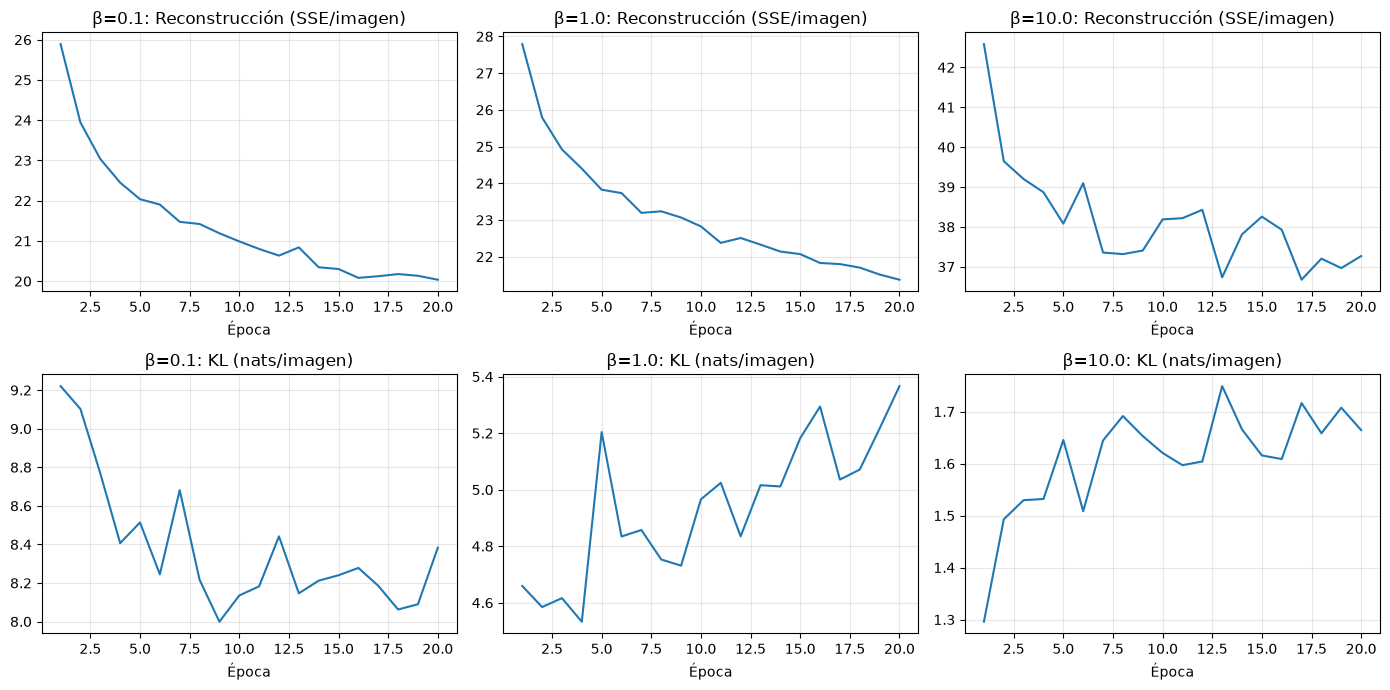

In [9]:
class VAE(nn.Module):
    def __init__(self, d=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(784,400), nn.ReLU(), nn.Linear(400,128), nn.ReLU())
        self.mu = nn.Linear(128,d); self.logvar = nn.Linear(128,d)
        self.dec = nn.Sequential(nn.Linear(d,128), nn.ReLU(), nn.Linear(128,400), nn.ReLU(), nn.Linear(400,784), nn.Sigmoid())
    def encode(self,x):
        h=self.enc(x); return self.mu(h), self.logvar(h)
    def decode(self,z): return self.dec(z).view(-1,1,28,28)
    def forward(self,x):
        mu,logvar=self.encode(x)
        z=mu+torch.exp(0.5*logvar)*torch.randn_like(mu)
        return self.decode(z),mu,logvar

def vae_terms(x,xhat,mu,logvar):
    rec=(x-xhat).square().flatten(1).sum(1)
    kl=-0.5*(1+logvar-mu.square()-logvar.exp()).sum(1)
    return rec,kl

def vae_epoch(model,loader,beta,opt=None):
    model.train(opt is not None); totals=torch.zeros(3); count=0
    for step,(x,_) in enumerate(loader):
        if FAST_DEV_RUN and step>=3: break
        x=x.to(device)
        with torch.set_grad_enabled(opt is not None):
            xhat,mu,logvar=model(x); rec,kl=vae_terms(x,xhat,mu,logvar)
            loss=(rec+beta*kl).mean()
            if opt is not None:
                opt.zero_grad(); loss.backward(); opt.step()
        totals+=torch.tensor([rec.sum().item(),kl.sum().item(),loss.item()*len(x)])
        count+=len(x)
    return (totals/count).tolist()

vae_models={}; vae_hist={}
for beta in beta_values:
    path=OUT/f'vae_beta_{beta}.pt'; model=VAE(latent_dim).to(device)
    hist={'train':[],'val':[]}
    if path.exists() and not FAST_DEV_RUN:
        checkpoint=torch.load(path,map_location=device,weights_only=False)
        model.load_state_dict(checkpoint['model']); hist=checkpoint['history']
        print('Checkpoint cargado:',path)
    else:
        opt=torch.optim.Adam(model.parameters(),lr=lr_vae)
        for epoch in range(2 if FAST_DEV_RUN else epochs_vae):
            tr=vae_epoch(model,train_loader,beta,opt); va=vae_epoch(model,val_loader,beta)
            hist['train'].append(tr);hist['val'].append(va)
            print(f'beta={beta} época {epoch+1}: val_rec={va[0]:.3f} val_KL={va[1]:.3f}')
        if not FAST_DEV_RUN: torch.save({'model':model.state_dict(),'history':hist},path)
    model.eval();vae_models[beta]=model;vae_hist[beta]=hist
fig,ax=plt.subplots(2,3,figsize=(14,7))
for j,beta in enumerate(beta_values):
    h=np.asarray(vae_hist[beta]['val'])
    for i,name in enumerate(['Reconstrucción (SSE/imagen)','KL (nats/imagen)']):
        ax[i,j].plot(np.arange(1,len(h)+1),h[:,i]);ax[i,j].set(title=f'β={beta}: {name}',xlabel='Época');ax[i,j].grid(alpha=.3)
plt.tight_layout();plt.show()

### Task 1.3 — Explorar el espacio latente
Las proyecciones de μ permiten observar cómo se distribuyen las clases. La cuadrícula de decodificación, las muestras aleatorias y las interpolaciones ayudan a examinar continuidad, diversidad y calidad visual.

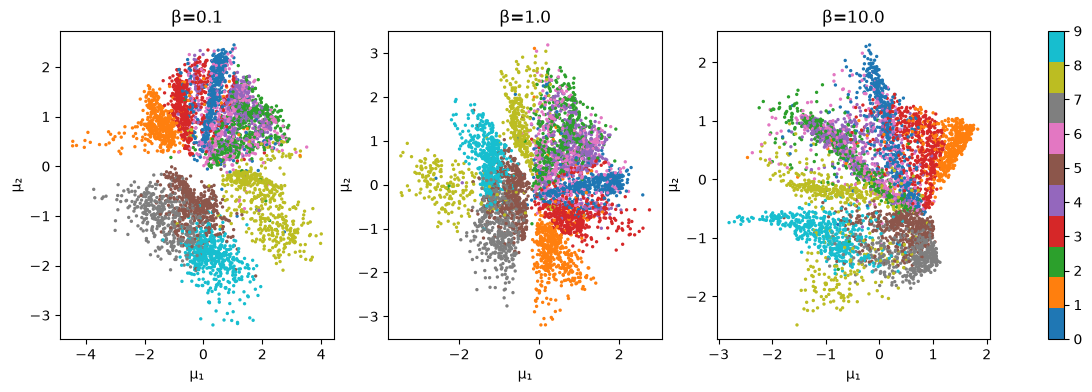

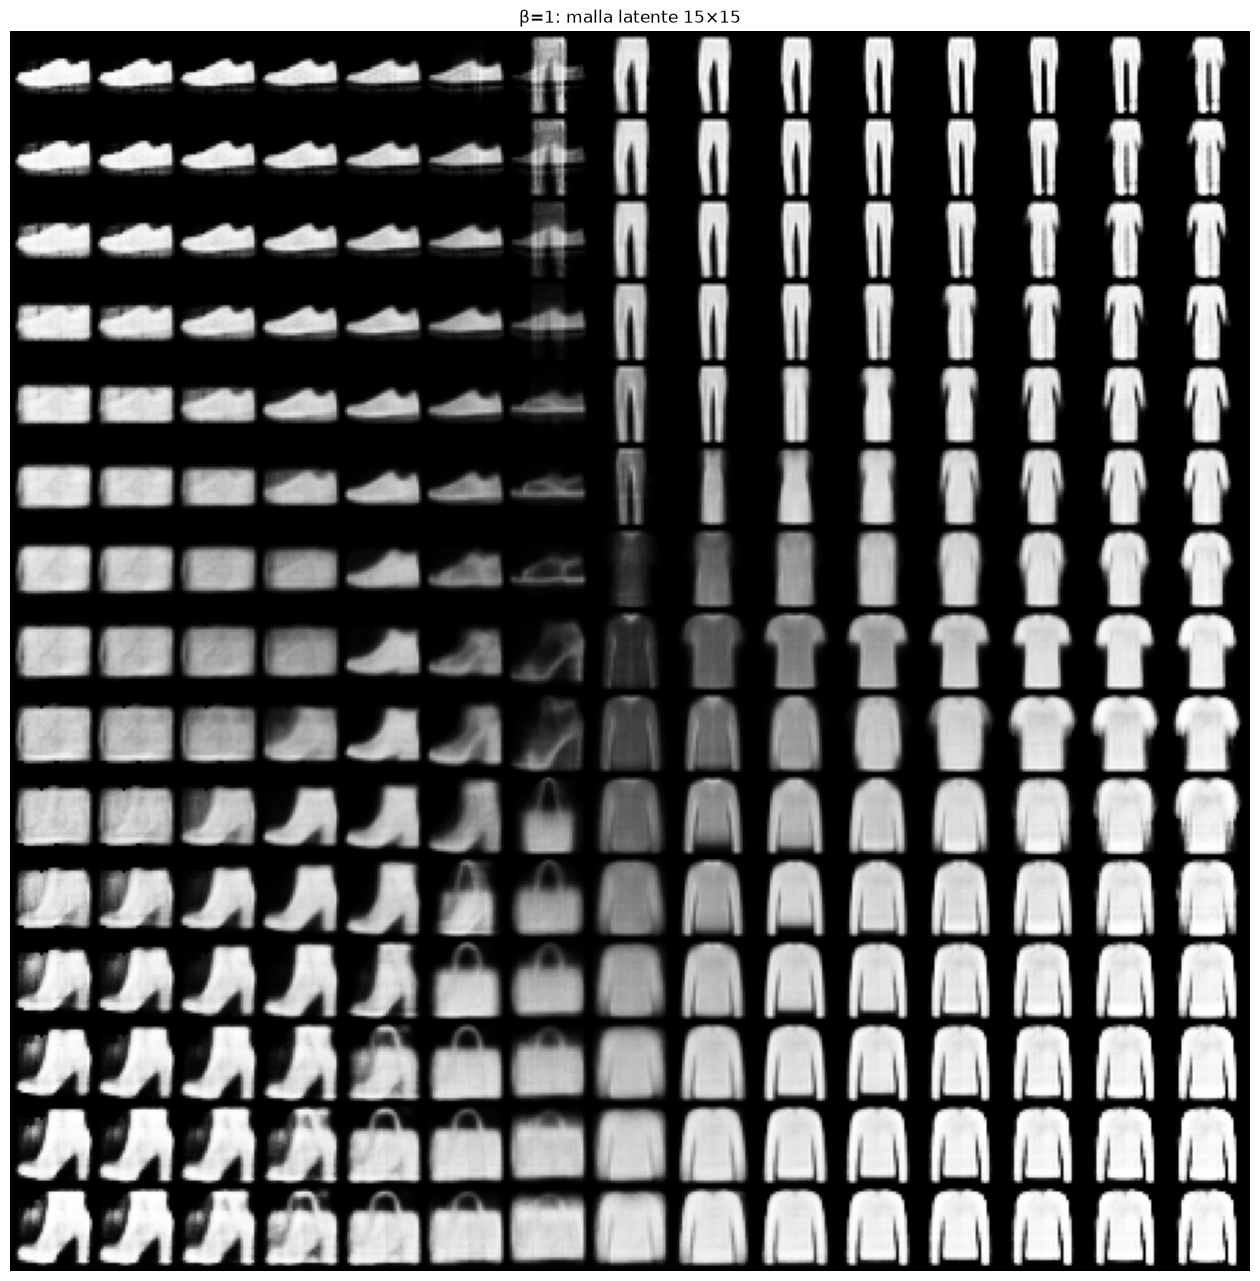

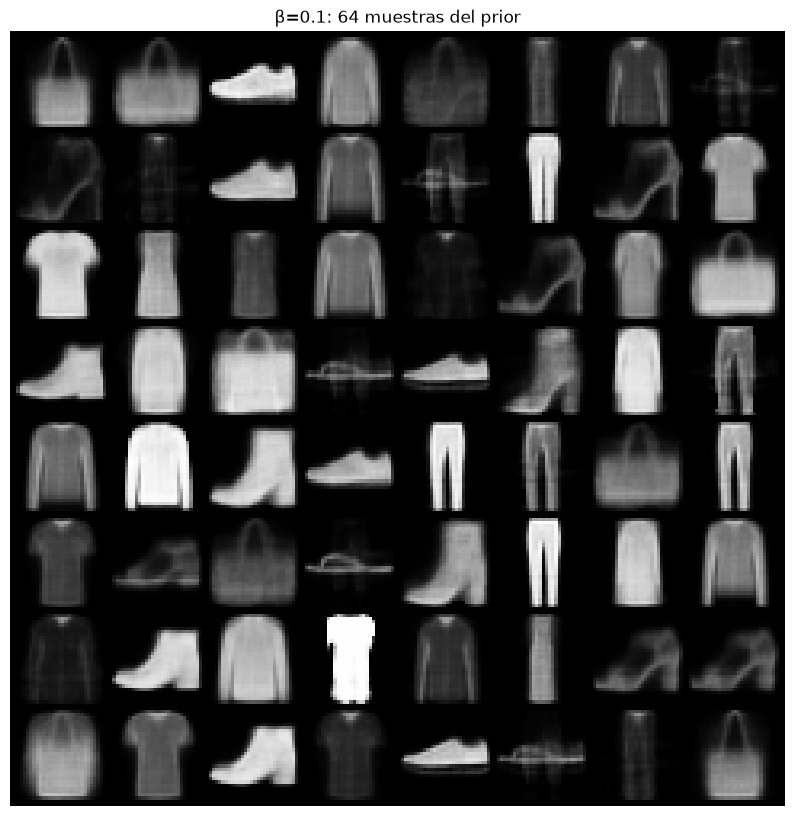

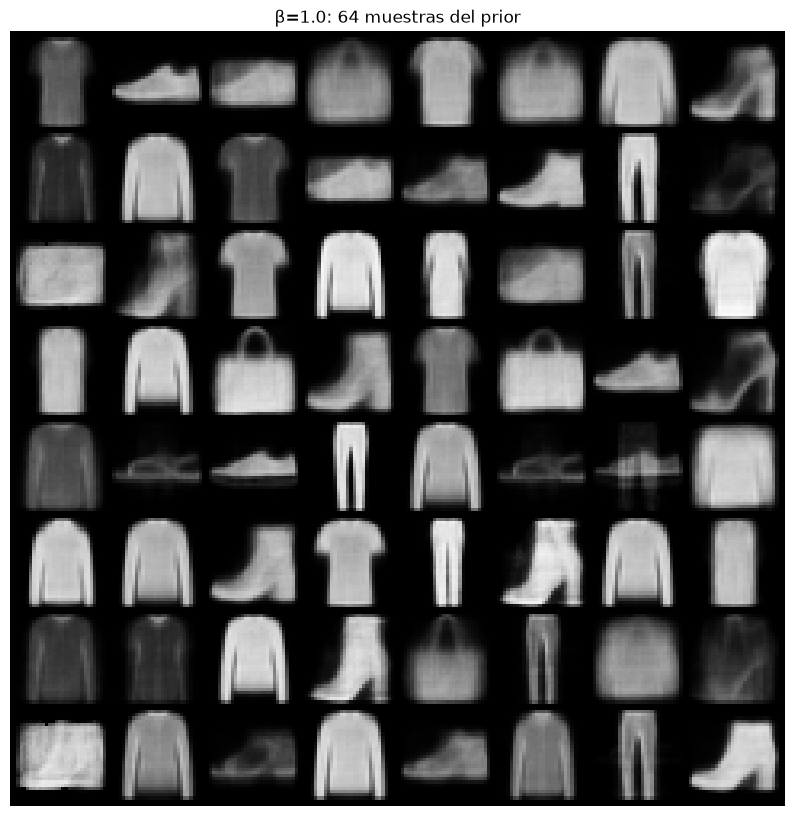

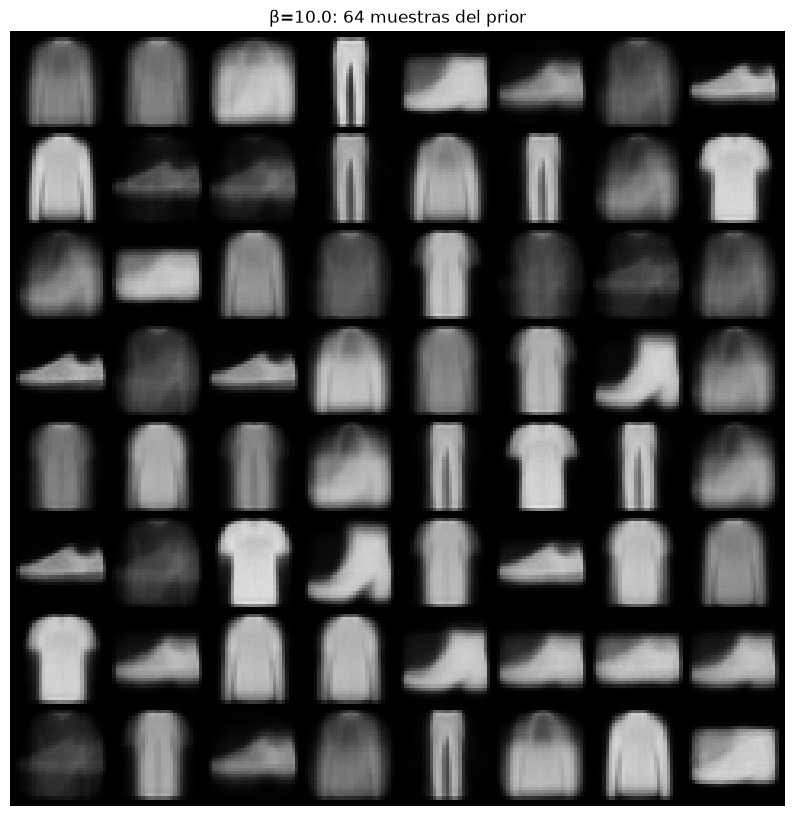

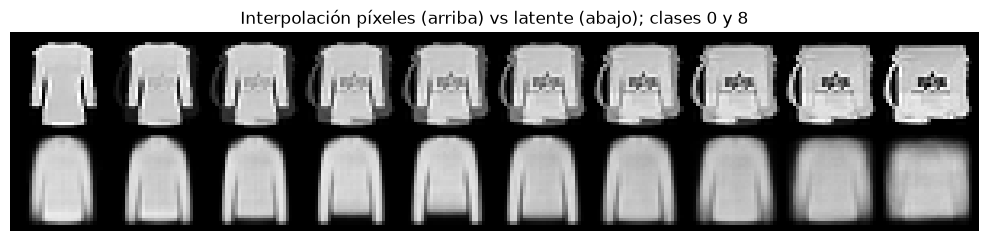

In [10]:
@torch.no_grad()
def get_val_latents(model):
    mus=[];ys=[]
    for x,y in val_loader:
        mu,_=model.encode(x.to(device));mus.append(mu.cpu());ys.append(y)
    return torch.cat(mus),torch.cat(ys)
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,beta in zip(axs,beta_values):
    mu,y=get_val_latents(vae_models[beta]);sc=ax.scatter(mu[:,0],mu[:,1],c=y,s=2,cmap='tab10',vmin=0,vmax=9)
    ax.set(title=f'β={beta}',xlabel='μ₁',ylabel='μ₂')
fig.colorbar(sc,ax=axs.ravel().tolist(),ticks=range(10));plt.show()

def show_images(imgs,nrow=8,title=''):
    grid=make_grid(imgs.detach().cpu(),nrow=nrow,padding=2,normalize=False)
    plt.figure(figsize=(min(16,nrow*1.25),max(2,math.ceil(len(imgs)/nrow)*1.3)))
    plt.imshow(grid.permute(1,2,0).clamp(0,1));plt.axis('off');plt.title(title);plt.show()

with torch.no_grad():
    v=vae_models[1.0]
    vals=torch.linspace(-3,3,15,device=device)
    z=torch.stack([torch.tensor([a,b],device=device) for b in vals for a in vals])
    show_images(v.decode(z),15,'β=1: malla latente 15×15')
    for beta in beta_values:
        z=torch.randn(64,latent_dim,device=device)
        show_images(vae_models[beta].decode(z),8,f'β={beta}: 64 muestras del prior')
    x1,y1=val_set[0]
    x2,y2=next((x,y) for x,y in val_set if y!=y1)
    x1=x1[None].to(device);x2=x2[None].to(device)
    m1,_=v.encode(x1);m2,_=v.encode(x2)
    a=torch.linspace(0,1,10,device=device).view(-1,1,1,1)
    pix=(1-a)*x1+a*x2
    lat=v.decode((1-a.flatten()[:,None])*m1+a.flatten()[:,None]*m2)
    show_images(torch.cat([pix,lat]),10,f'Interpolación píxeles (arriba) vs latente (abajo); clases {y1} y {y2}')

### Task 1.4 — Evaluación e interpretación del VAE
Se comparan reconstrucción y KL (en nats y bits), se contrasta la KL analítica con una estimación Monte Carlo y se mide la nitidez. **Precaución:** la KL promedio no es exactamente la información que z conserva sobre la etiqueta; la comparación con log₂(10) sirve como referencia, no como igualdad.

In [11]:
rows=[]
for beta in beta_values:
    rec,kl,_=vae_hist[beta]['val'][-1]
    rows.append({'beta':beta,'recon_SSE':rec,'KL_nats':kl,'KL_bits':kl/math.log(2)})
vae_table=pd.DataFrame(rows);display(vae_table)
print('Bits para 10 clases:',math.log2(10))
# KL Monte Carlo para una imagen: log q - log p, constantes se cancelan.
with torch.no_grad():
    x,_=val_set[0];mu,lv=vae_models[1.0].encode(x[None].to(device))
    analytic=(-.5*(1+lv-mu.square()-lv.exp()).sum()).item()
    eps=torch.randn(100000,latent_dim,device=device)
    z=mu+torch.exp(.5*lv)*eps
    logratio=.5*(z.square()-((z-mu).square()/lv.exp())-lv).sum(dim=1)
    mc=logratio.mean().item();se=logratio.std(unbiased=True).item()/math.sqrt(len(logratio))
print(f'KL analítica={analytic:.6f}, MC={mc:.6f}, error relativo={abs(mc-analytic)/max(abs(analytic),1e-12):.3%}, SE_MC={se:.6f}, error/SE={abs(mc-analytic)/se:.2f}')

def sharpness(x): return (x[:,:,:,1:]-x[:,:,:,:-1]).abs().mean().item()
real_1000=torch.stack([val_set[i][0] for i in range(1000)])
sharp={'real':sharpness(real_1000)}
with torch.no_grad():
    for beta in beta_values:
        batches=[vae_models[beta].decode(torch.randn(min(128,1000-i),latent_dim,device=device)).cpu() for i in range(0,1000,128)]
        sharp[f'VAE β={beta}']=sharpness(torch.cat(batches))
print('Nitidez (diferencia horizontal media):',sharp)
print('Relación ELBO: sigma_x² = beta/2:',{beta:beta/2 for beta in beta_values})

,beta,recon_SSE,KL_nats,KL_bits
0,0.1,20.036064,8.382889,12.093952
1,1.0,21.372179,5.366554,7.742301
2,10.0,37.268951,1.664466,2.401317


Bits para 10 clases: 3.321928094887362
KL analítica=5.276077, MC=5.280780, error relativo=0.089%, SE_MC=0.003181, error/SE=1.48
Nitidez (diferencia horizontal media): {'real': 0.08914583176374435, 'VAE β=0.1': 0.04083579406142235, 'VAE β=1.0': 0.04951851814985275, 'VAE β=10.0': 0.04413597285747528}
Relación ELBO: sigma_x² = beta/2: {0.1: 0.05, 1.0: 0.5, 10.0: 5.0}


**Interpretación Task 1.4 (completar después de ejecutar):** Compare los valores de `vae_table` con 3.32 bits y el diagrama β=10; indique si se separan las clases. Evalúe si el error MC es razonable usando `error/SE` (aproximadamente 2 o menos es habitual). Inspeccione la cuadrícula e identifique coordenadas concretas de regiones no reconocibles. Compare los puntos medios de ambas interpolaciones. Discuta la pérdida de bordes usando `sharp` y la identidad σₓ²=β/2; no afirme conclusiones sin observar las imágenes.

## Task 2 — Proceso forward de difusión (entrega parcial)
### Task 2.1 — Calendario de ruido y expresión cerrada
Construimos βₜ, αₜ y el producto acumulado ᾱₜ con tensores de PyTorch. La expresión cerrada permite obtener xₜ sin simular todos los pasos anteriores.

In [12]:
T=1000;beta_start=1e-4;beta_end=0.02
betas=torch.linspace(beta_start,beta_end,T,device=device)
alphas=1-betas;abar=torch.cumprod(alphas,dim=0)

def q_sample(x0,t,eps,schedule=abar):
    # t en {1,...,T}, índice tensorial t-1.
    a=schedule[t.long()-1].view(-1,1,1,1)
    return a.sqrt()*x0+(1-a).sqrt()*eps

def to_diff(x): return 2*x-1

def to_image(x): return ((x+1)/2).clamp(0,1)

### Task 2.2 — Verificación estadística del proceso
Se comparan 5,000 trayectorias independientes con la media y varianza teóricas en t=300. El error estándar ayuda a interpretar las diferencias observadas.

In [13]:
x0=to_diff(val_set[0][0][None].to(device));copies=5000;step_t=300
with torch.no_grad():
    xs=x0.expand(copies,-1,-1,-1).clone()
    for s in range(step_t):
        xs=alphas[s].sqrt()*xs+betas[s].sqrt()*torch.randn_like(xs)
    mean_emp=xs.mean(0);var_emp=xs.var(0,unbiased=True)
    mean_th=abar[step_t-1].sqrt()*x0[0];var_th=1-abar[step_t-1]
    maxerr=(mean_emp-mean_th).abs().max().item()
    se=math.sqrt(var_th.item()/copies)
    print('Máximo error media:',maxerr,'| SE teórico por píxel:',se,'| máximo/SE:',maxerr/se)
    print('Varianza empírica media:',var_emp.mean().item(),'| teórica:',var_th.item())
    print('Nota: el máximo sobre 784 píxeles suele superar varias veces el SE individual.')
    del xs

Máximo error media: 0.03831684589385986 | SE teórico por píxel: 0.010987086019865151 | máximo/SE: 3.487443879531048
Varianza empírica media: 0.6037111282348633 | teórica: 0.6035802960395813
Nota: el máximo sobre 784 píxeles suele superar varias veces el SE individual.


### Task 2.3 — Evolución visual y relación señal-ruido
Las imágenes con distintos niveles de ruido se interpretan junto con ᾱₜ y SNR(t). Se identifican los pasos en los que la señal deja de dominar.

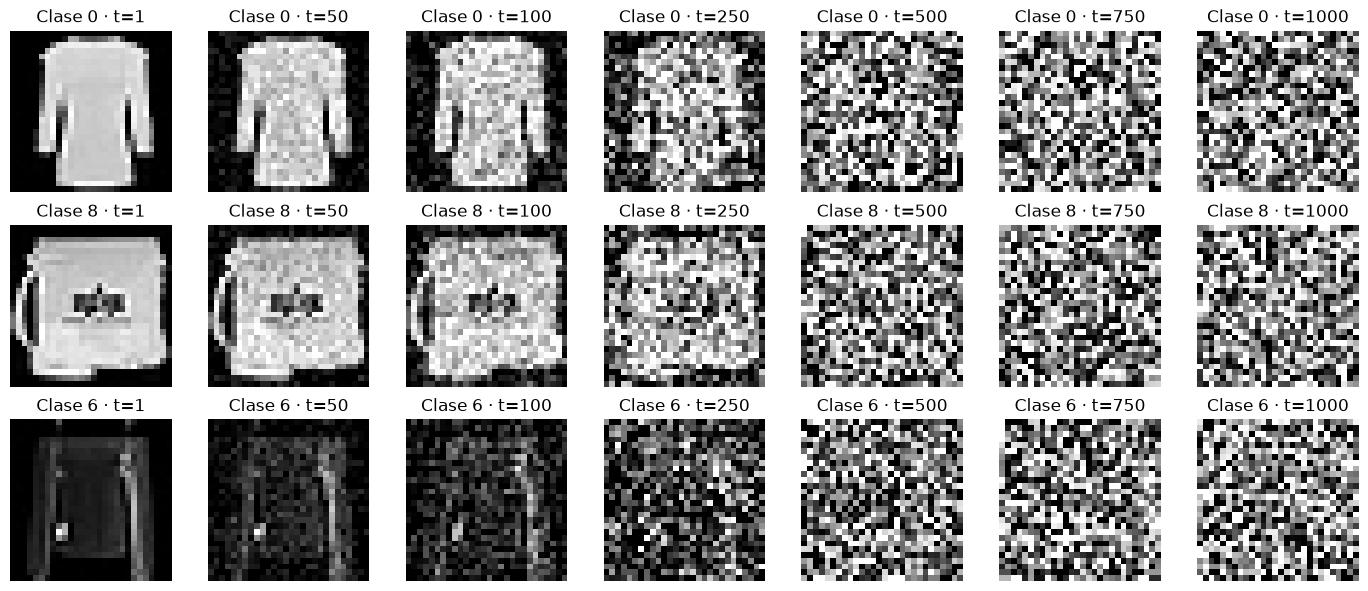

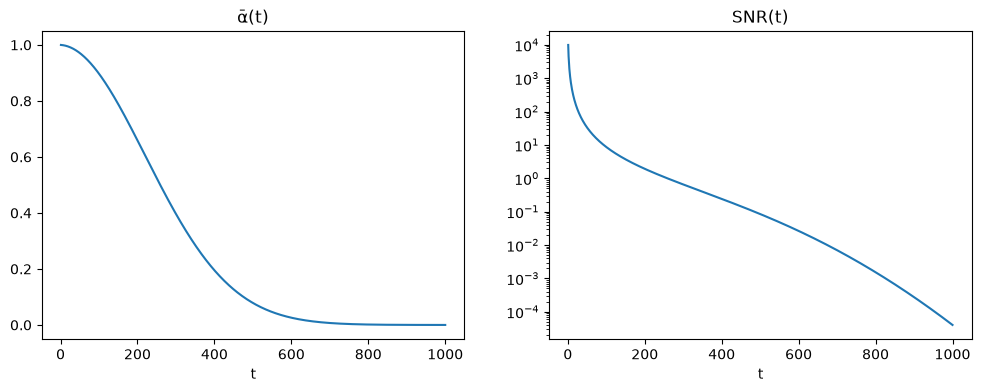

Primer t con SNR<1: 260 | Primer t con ᾱ<0.01: 674


In [14]:
times=[1,50,100,250,500,750,1000]
chosen=[];seen=set()
for x,y in val_set:
    if y not in seen: chosen.append((x,y));seen.add(y)
    if len(chosen)==3:break
fig,axs=plt.subplots(3,len(times),figsize=(14,6))
with torch.no_grad():
    for i,(x,y) in enumerate(chosen):
        x=to_diff(x[None].to(device))
        for j,t in enumerate(times):
            noisy=q_sample(x,torch.tensor([t],device=device),torch.randn_like(x))
            axs[i,j].imshow(to_image(noisy[0,0]).cpu(),cmap='gray',vmin=0,vmax=1)
            axs[i,j].set(title=f'Clase {y} · t={t}');axs[i,j].axis('off')
plt.tight_layout();plt.show()
snr=abar/(1-abar);ts=np.arange(1,T+1)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(ts,abar.cpu());axs[0].set(title='ᾱ(t)',xlabel='t')
axs[1].semilogy(ts,snr.cpu());axs[1].set(title='SNR(t)',xlabel='t')
plt.show()
def first_true(mask):
    idx=torch.where(mask)[0];return int(idx[0])+1 if len(idx) else None
print('Primer t con SNR<1:',first_true(snr<1),'| Primer t con ᾱ<0.01:',first_true(abar<.01))

### Task 2.4 — Segundo calendario original
Propuesta: βₜ = β_min + (β_max − β_min)(t/T)² con β_max=0.035. Se comprueban los requisitos βₜ∈(0,1) y ᾱ_T<10⁻³; no se utiliza calendario prefabricado.

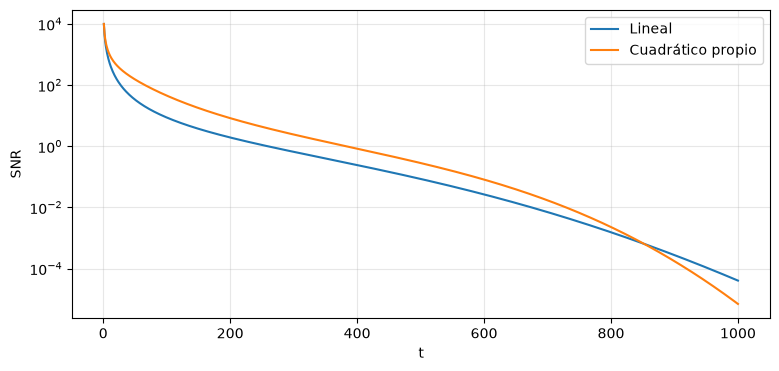

Lineal ᾱ_T: 4.0358307160204276e-05 primer SNR<1: 260 pasos SNR en [0.01,100]: 647
Cuadrático ᾱ_T: 6.954216587473638e-06 primer SNR<1: 383 pasos SNR en [0.01,100]: 664


In [15]:
u=torch.linspace(1/T,1,T,device=device)
betas_alt=beta_start+(0.035-beta_start)*u.square()
abar_alt=torch.cumprod(1-betas_alt,dim=0)
snr_alt=abar_alt/(1-abar_alt)
assert bool(((betas_alt>0)&(betas_alt<1)).all()) and abar_alt[-1].item()<1e-3
plt.figure(figsize=(9,4));plt.semilogy(ts,snr.cpu(),label='Lineal');plt.semilogy(ts,snr_alt.cpu(),label='Cuadrático propio')
plt.xlabel('t');plt.ylabel('SNR');plt.legend();plt.grid(alpha=.3);plt.show()
for name,a,s in [('Lineal',abar,snr),('Cuadrático',abar_alt,snr_alt)]:
    print(name,'ᾱ_T:',a[-1].item(),'primer SNR<1:',first_true(s<1),'pasos SNR en [0.01,100]:',int(((s>=.01)&(s<=100)).sum()))

### Task 2.5 — Aproximaciones y utilidad de los pasos de difusión
Se contrasta la aproximación de log ᾱ_T con el valor calculado, se cuentan los pasos en rangos relevantes de SNR y se comprueba la identidad de varianzas.

In [16]:
# Aproximación analítica: suma aritmética de β y aproximación integral de la suma de β².
sum_b=T*(beta_start+beta_end)/2
sum_b2_integral=T*(beta_start**2+beta_start*beta_end+beta_end**2)/3
approx=math.exp(-sum_b-.5*sum_b2_integral)
print(f'Σβ={sum_b:.8f}, Σβ² (integral)≈{sum_b2_integral:.8f}, ᾱ_T aprox≈{approx:.8g}, ᾱ_T exacta={abar[-1].item():.8g}')
# Varianza global: E sobre píxeles e imágenes; muestreo independiente de ruido.
with torch.no_grad():
    raw=raw_train.data.float().to(device)/255*2-1
    var0=raw.var(unbiased=False).item()
    print('Var(x0) global:',var0)
    for t in [1,250,500,1000]:
        # muestra de 5000 imágenes para reducir memoria y ruido de estimación
        x=raw[:5000,None];noise=torch.randn_like(x)
        xt=q_sample(x,torch.full((len(x),),t,device=device),noise)
        predicted=abar[t-1].item()*var0+(1-abar[t-1].item())
        print(f't={t:4d}: var empírica={xt.var(unbiased=False).item():.6f}, var teórica={predicted:.6f}')
    del raw

Σβ=10.05000000, Σβ² (integral)≈0.13400333, ᾱ_T aprox≈4.0387038e-05, ᾱ_T exacta=4.0358307e-05
Var(x0) global: 0.49850448966026306
t=   1: var empírica=0.502386, var teórica=0.498555
t= 250: var empírica=0.739275, var teórica=0.737174
t= 500: var empírica=0.961654, var teórica=0.960589
t=1000: var empírica=1.000758, var teórica=0.999980


**Demostración:** si `x₀` y `ε` son independientes y `Var(ε)=1`, entonces `Var(√ᾱ x₀+√(1−ᾱ) ε)=ᾱ Var(x₀)+(1−ᾱ)`. En el límite ᾱ_T≈0 la varianza se aproxima a 1, necesaria para iniciar desde N(0,I). **Interpretación:** cuando SNR es muy bajo, ε se recupera casi directamente de xₜ; cuando es muy alto, el ruido queda oculto por la señal. Compare los conteos de pasos informativos de ambos calendarios; eficiencia aquí es una heurística, no una medida de calidad final. La estimación de media en Task 2.2 tiene SE=√((1−ᾱ₃₀₀)/5000) por píxel; el máximo entre 784 píxeles requiere cautela.

## Task 3 — Difusión condicional (entrega final)
### Task 3.1 — U-Net pequeña con información temporal y de clase
La red procesa imágenes de 28×28 y 14×14. El embedding sinusoidal representa t y el embedding de clase incluye el índice 10 para la condición nula; ambos se combinan para condicionar los bloques.

In [17]:
def sinusoidal_embedding(t,dim=64):
    half=dim//2
    freq=torch.exp(-math.log(10000)*torch.arange(half,device=t.device).float()/half)
    phase=t.float()[:,None]*freq[None,:]
    return torch.cat([phase.sin(),phase.cos()],dim=-1)

class ResBlock(nn.Module):
    def __init__(self,cin,cout,embdim):
        super().__init__()
        self.c1=nn.Conv2d(cin,cout,3,padding=1);self.c2=nn.Conv2d(cout,cout,3,padding=1)
        self.g1=nn.GroupNorm(8,cout);self.g2=nn.GroupNorm(8,cout)
        self.emb=nn.Linear(embdim,cout)
        self.skip=nn.Conv2d(cin,cout,1) if cin!=cout else nn.Identity()
    def forward(self,x,e):
        h=F.silu(self.g1(self.c1(x)))
        h=h+self.emb(e)[:,:,None,None]
        h=self.g2(self.c2(F.silu(h)))
        return F.silu(h+self.skip(x))

class TinyUNet(nn.Module):
    def __init__(self,embdim=128):
        super().__init__()
        self.temb=nn.Sequential(nn.Linear(64,embdim),nn.SiLU(),nn.Linear(embdim,embdim))
        self.cemb=nn.Embedding(11,embdim)
        self.stem=nn.Conv2d(1,32,3,padding=1)
        self.down1=ResBlock(32,32,embdim)
        self.pool=nn.Conv2d(32,64,3,stride=2,padding=1)
        self.down2=ResBlock(64,64,embdim)
        self.mid=ResBlock(64,64,embdim)
        self.up=nn.ConvTranspose2d(64,32,4,stride=2,padding=1)
        self.up1=ResBlock(64,32,embdim)
        self.final=nn.Conv2d(32,1,3,padding=1)
    def forward(self,x,t,c):
        e=self.temb(sinusoidal_embedding(t,64))+self.cemb(c)
        h0=self.down1(self.stem(x),e)    # B×32×28×28
        h1=self.down2(self.pool(h0),e)  # B×64×14×14
        h2=self.mid(h1,e)               # B×64×14×14
        h3=self.up(h2)                  # B×32×28×28
        return self.final(self.up1(torch.cat([h3,h0],dim=1),e))

unet=TinyUNet().to(device)
print('Parámetros U-Net:',sum(p.numel() for p in unet.parameters()))
assert unet(torch.randn(2,1,28,28,device=device),torch.tensor([1,1000],device=device),torch.tensor([0,10],device=device)).shape==(2,1,28,28)

Parámetros U-Net: 299681


### Task 3.2 — Entrenar la predicción de ruido
Para cada imagen se eligen t y ε aleatoriamente. El modelo aprende a estimar ε a partir de xₜ, t y la etiqueta, que se sustituye por la condición nula con probabilidad 0.1. La validación se separa en diez intervalos de tiempo.

Época 1/30: MSE=0.12134
Época 2/30: MSE=0.06250
Época 3/30: MSE=0.05438
Época 4/30: MSE=0.05161
Época 5/30: MSE=0.04946
Época 6/30: MSE=0.04895
Época 7/30: MSE=0.04715
Época 8/30: MSE=0.04594
Época 9/30: MSE=0.04572
Época 10/30: MSE=0.04478
Época 11/30: MSE=0.04406
Época 12/30: MSE=0.04433
Época 13/30: MSE=0.04387
Época 14/30: MSE=0.04323
Época 15/30: MSE=0.04319
Época 16/30: MSE=0.04317
Época 17/30: MSE=0.04199
Época 18/30: MSE=0.04219
Época 19/30: MSE=0.04200
Época 20/30: MSE=0.04213
Época 21/30: MSE=0.04128
Época 22/30: MSE=0.04157
Época 23/30: MSE=0.04177
Época 24/30: MSE=0.04110
Época 25/30: MSE=0.04110
Época 26/30: MSE=0.04072
Época 27/30: MSE=0.04086
Época 28/30: MSE=0.04120
Época 29/30: MSE=0.04059
Época 30/30: MSE=0.04043


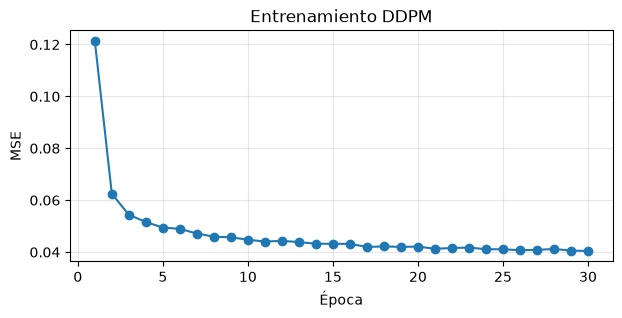

In [18]:
epochs_diff=30;batch_size_diff=128;lr_diff=2e-4;p_uncond=.1
unet_path=OUT/'unet_conditional.pt';diff_hist=[]
if unet_path.exists() and not FAST_DEV_RUN:
    checkpoint=torch.load(unet_path,map_location=device,weights_only=False)
    unet.load_state_dict(checkpoint['model']);diff_hist=checkpoint['history'];print('U-Net cargada')
else:
    optimizer=torch.optim.Adam(unet.parameters(),lr=lr_diff)
    for epoch in range(2 if FAST_DEV_RUN else epochs_diff):
        unet.train();total=0.;count=0
        for step,(x,c) in enumerate(train_loader):
            if FAST_DEV_RUN and step>=3:break
            x=to_diff(x.to(device));c=c.to(device)
            t=torch.randint(1,T+1,(len(x),),device=device)
            eps=torch.randn_like(x);xt=q_sample(x,t,eps)
            c=torch.where(torch.rand(len(c),device=device)<p_uncond,10,c)
            loss=F.mse_loss(unet(xt,t,c),eps)
            optimizer.zero_grad();loss.backward();optimizer.step()
            total+=loss.item()*len(x);count+=len(x)
        diff_hist.append(total/count);print(f'Época {epoch+1}/{epochs_diff}: MSE={diff_hist[-1]:.5f}')
    if not FAST_DEV_RUN:torch.save({'model':unet.state_dict(),'history':diff_hist},unet_path)
unet.eval()
plt.figure(figsize=(7,3));plt.plot(range(1,len(diff_hist)+1),diff_hist,marker='o');plt.xlabel('Época');plt.ylabel('MSE');plt.title('Entrenamiento DDPM');plt.grid(alpha=.3);plt.show()

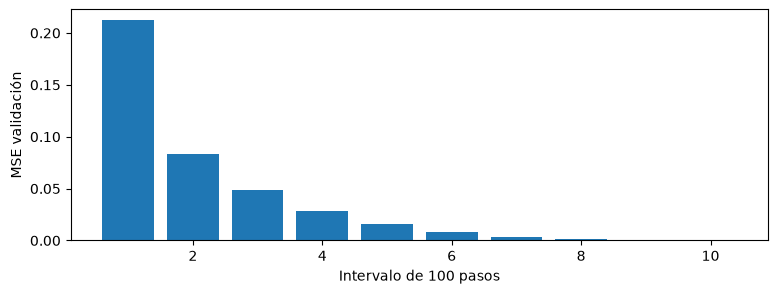

Máxima pérdida: intervalo 1 | mínima: 10


In [19]:
# Evaluación por intervalos temporales: cada tramo utiliza las 5,000 imágenes de validación.
@torch.no_grad()
def validate_diff_bins(model):
    model.eval();means=[]
    for bin_idx in range(10):
        total=0.;count=0
        for step,(x,c) in enumerate(val_loader):
            if FAST_DEV_RUN and step>=3:break
            x=to_diff(x.to(device));c=c.to(device)
            t=torch.randint(bin_idx*100+1,(bin_idx+1)*100+1,(len(x),),device=device)
            eps=torch.randn_like(x)
            mse=(model(q_sample(x,t,eps),t,c)-eps).square().flatten(1).mean(1)
            total+=mse.sum().item();count+=len(x)
        means.append(total/count)
    return means
bin_losses=validate_diff_bins(unet)
plt.figure(figsize=(9,3));plt.bar(range(1,11),bin_losses);plt.xlabel('Intervalo de 100 pasos');plt.ylabel('MSE validación');plt.show()
print('Máxima pérdida: intervalo',np.argmax(bin_losses)+1,'| mínima:',np.argmin(bin_losses)+1)

### Task 3.3 — Muestreo ancestral
Implementación explícita: `x_(t-1) = (x_t - β_t / √(1−ᾱ_t) ε̂)/√α_t + √β_t z`, con z=0 cuando t=1. En la generación se hace **una evaluación de red por paso** si w=1.

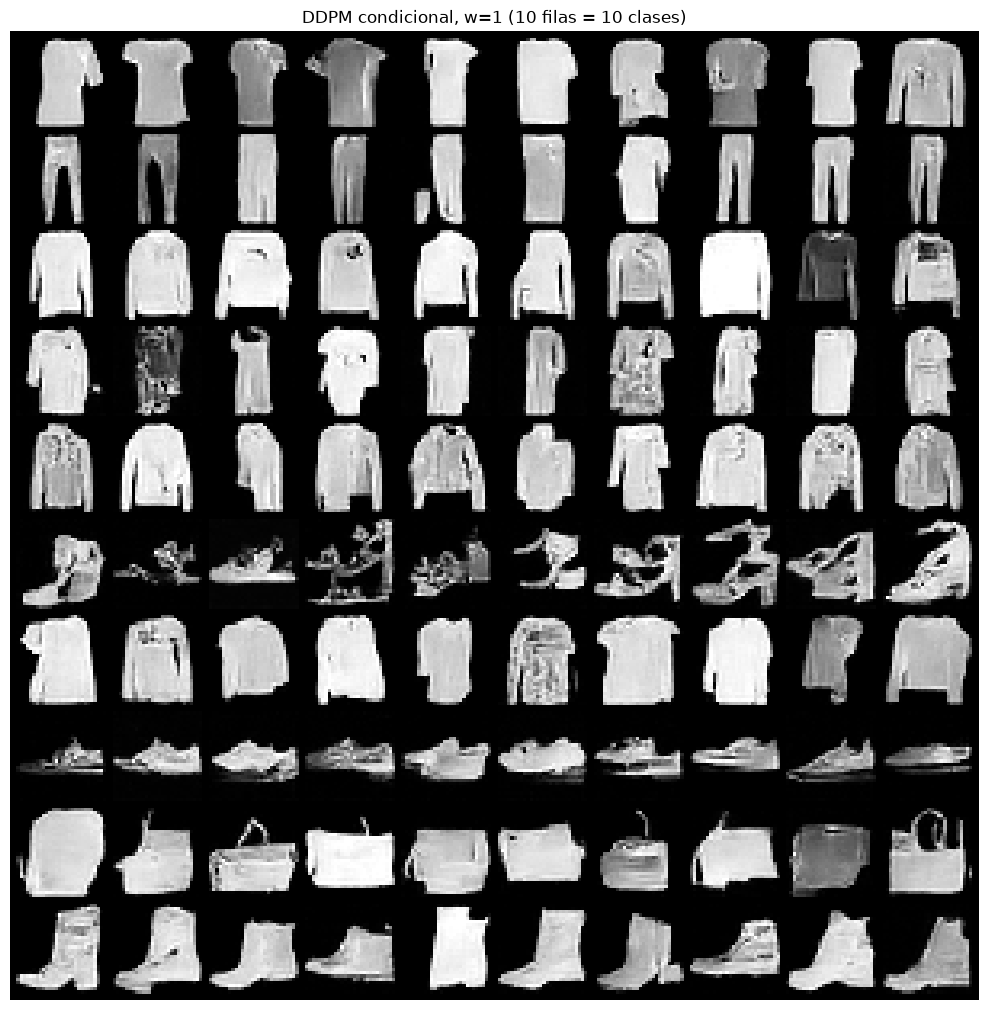

In [20]:
@torch.no_grad()
def sample_ddpm(model,classes,w=1.0,initial_noise=None):
    model.eval();classes=classes.to(device).long()
    x=torch.randn(len(classes),1,28,28,device=device) if initial_noise is None else initial_noise.to(device).clone()
    for ti in range(T,0,-1):
        t=torch.full((len(classes),),ti,device=device,dtype=torch.long)
        cond=model(x,t,classes)
        if w==1:
            pred=cond
        else:
            uncond=model(x,t,torch.full_like(classes,10))
            pred=uncond+w*(cond-uncond)
        x=(x-(betas[ti-1]/torch.sqrt(1-abar[ti-1]))*pred)/torch.sqrt(alphas[ti-1])
        if ti>1:x=x+torch.sqrt(betas[ti-1])*torch.randn_like(x)
    return x.clamp(-1,1)

# 10 imágenes por clase (100 imágenes, 1000 pasos).
classes100=torch.arange(10).repeat_interleave(10).to(device)
path100=OUT/'diff_10_por_clase.pt'
if path100.exists() and not FAST_DEV_RUN: samples100=torch.load(path100,map_location='cpu',weights_only=True)
else:
    samples100=sample_ddpm(unet,classes100).cpu()
    if not FAST_DEV_RUN:torch.save(samples100,path100)
show_images(to_image(samples100),10,'DDPM condicional, w=1 (10 filas = 10 clases)')

### Task 3.4 — Intensidad de guía y evaluación de muestras
Se generan imágenes con w=1, 3 y 7. Un clasificador entrenado con imágenes reales estima la fidelidad a la clase solicitada; la diversidad se calcula mediante distancias entre imágenes de la misma clase. Ambas métricas deben interpretarse conjuntamente.

In [21]:
class FashionClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.head=nn.Sequential(nn.Flatten(),nn.Linear(64*7*7,128),nn.ReLU(),nn.Linear(128,10))
    def forward(self,x):return self.head(self.features(x))

classifier=FashionClassifier().to(device);clf_path=OUT/'fashion_classifier.pt';clf_hist=[]
@torch.no_grad()
def classifier_accuracy(model,loader):
    model.eval();correct=0;total=0
    for x,y in loader:
        correct+=(model(x.to(device)).argmax(1)==y.to(device)).sum().item();total+=len(y)
    return correct/total

if clf_path.exists() and not FAST_DEV_RUN:
    checkpoint=torch.load(clf_path,map_location=device,weights_only=False)
    classifier.load_state_dict(checkpoint['model']);clf_hist=checkpoint['history']
else:
    opt=torch.optim.Adam(classifier.parameters(),lr=1e-3)
    for epoch in range(2 if FAST_DEV_RUN else 20):
        classifier.train()
        for step,(x,y) in enumerate(train_loader):
            if FAST_DEV_RUN and step>=3:break
            loss=F.cross_entropy(classifier(x.to(device)),y.to(device))
            opt.zero_grad();loss.backward();opt.step()
        acc=classifier_accuracy(classifier,val_loader);clf_hist.append(acc)
        print(f'Clasificador época {epoch+1}: val_acc={acc:.2%}')
        if acc>=.88 and not FAST_DEV_RUN:break
    if not FAST_DEV_RUN:torch.save({'model':classifier.state_dict(),'history':clf_hist},clf_path)
classifier.eval();clf_acc=classifier_accuracy(classifier,val_loader)
print('Exactitud validación:',clf_acc)
if not FAST_DEV_RUN:assert clf_acc>=.88,'El clasificador no alcanzó 88%; ajustar entrenamiento antes de reportar fidelidad.'

Clasificador época 1: val_acc=85.56%
Clasificador época 2: val_acc=89.08%
Exactitud validación: 0.8908


Diversidad real media: 8.837591171264648


,w,fidelidad,diversidad,segundos_por_100
0,1,0.768,8.898829,49.127158
1,3,0.956,7.767658,103.435458
2,7,0.984,7.349772,123.391184


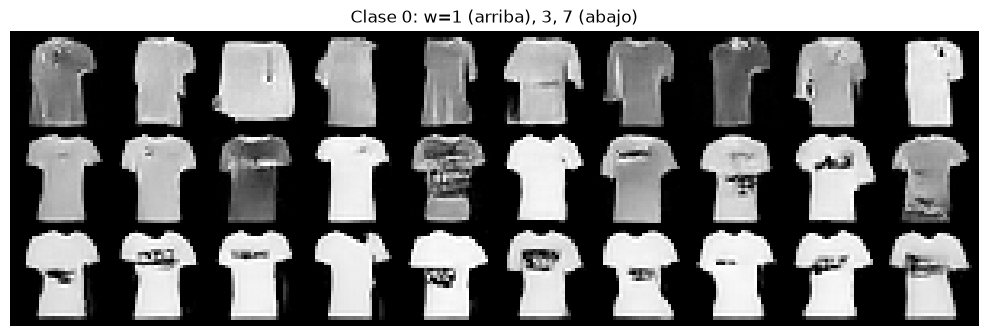

In [22]:
def class_diversity(images,labels):
    values={}
    for c in range(10):
        group=images[labels==c].flatten(1).float()
        values[c]=torch.pdist(group,p=2).mean().item() if len(group)>1 else float('nan')
    return values

real_images=torch.stack([val_set[i][0] for i in range(500)])  # reemplazamos abajo por 50 de cada clase
real_groups=[]
for c in range(10):
    idx=[i for i in range(len(val_set)) if val_set[i][1]==c][:50]
    assert len(idx)==50
    real_groups.extend(val_set[i][0] for i in idx)
real_500=torch.stack(real_groups)
real_labels=torch.arange(10).repeat_interleave(50)
real_div=class_diversity(real_500,real_labels)
print('Diversidad real media:',np.mean(list(real_div.values())))

classes500=torch.arange(10).repeat_interleave(50)
results={};generated={}
for w in [1,3,7]:
    file=OUT/f'diff_w{w}_500.pt'
    if file.exists() and not FAST_DEV_RUN:
        payload=torch.load(file,map_location='cpu',weights_only=False)
        images=payload['images'];elapsed=payload['seconds']
    else:
        chunks=[];elapsed=0.
        for start in range(0,500,50):
            c=classes500[start:start+50].to(device)
            if device.type=='cuda':torch.cuda.synchronize()
            t0=time.perf_counter();batch=sample_ddpm(unet,c,w=w)
            if device.type=='cuda':torch.cuda.synchronize()
            elapsed+=time.perf_counter()-t0;chunks.append(batch.cpu())
        images=torch.cat(chunks)
        if not FAST_DEV_RUN:torch.save({'images':images,'seconds':elapsed},file)
    generated[w]=images
    imgs01=to_image(images)
    div=class_diversity(imgs01,classes500)
    with torch.no_grad():
        predictions=torch.cat([classifier(chunk.to(device)).argmax(1).cpu() for chunk in imgs01.split(128)])
    fidelity=(predictions==classes500).float().mean().item()
    results[w]={'w':w,'fidelidad':fidelity,'diversidad':np.mean(list(div.values())),
                'segundos_por_100':elapsed/5,'diversidad_por_clase':div,'predicciones':predictions}
metrics_df=pd.DataFrame([{k:v for k,v in d.items() if k not in ('diversidad_por_clase','predicciones')} for d in results.values()])
display(metrics_df)
show_images(torch.cat([to_image(generated[w][0:10]) for w in [1,3,7]]),10,'Clase 0: w=1 (arriba), 3, 7 (abajo)')

### Task 3.5 — Interpretación de fidelidad, diversidad y confusiones
Las conclusiones deben apoyarse en las métricas por clase, las imágenes generadas, la matriz de confusión y la pérdida según el intervalo temporal.

Disminución de diversidad w=1→7: {0: 1.1883978843688965, 1: 0.960848331451416, 2: 3.656386375427246, 3: 0.8285512924194336, 4: 3.276797294616699, 5: -1.895909309387207, 6: 1.896904468536377, 7: 1.6248831748962402, 8: 1.312169075012207, 9: 2.6415438652038574} | mayor caída: 2


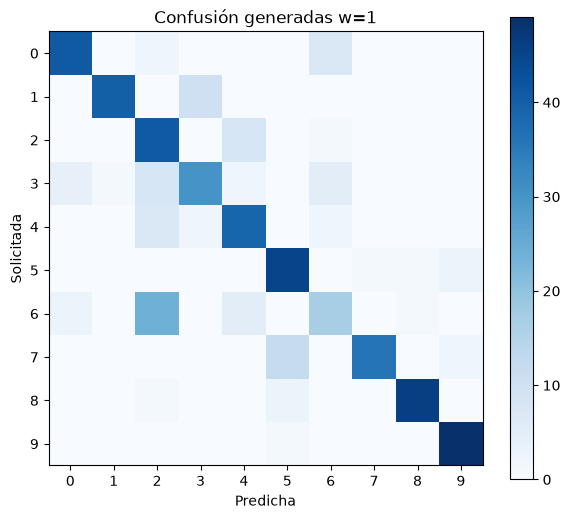

Par dirigido de mayor confusión (solicitada→predicha): 6 → 2 cantidad: 24


In [23]:
div_change={c:results[1]['diversidad_por_clase'][c]-results[7]['diversidad_por_clase'][c] for c in range(10)}
print('Disminución de diversidad w=1→7:',div_change,'| mayor caída:',max(div_change,key=div_change.get))
conf=torch.zeros(10,10,dtype=torch.int64)
for truth,pred in zip(classes500,results[1]['predicciones']):conf[int(truth),int(pred)]+=1
plt.figure(figsize=(7,6));plt.imshow(conf,cmap='Blues');plt.colorbar();plt.xticks(range(10));plt.yticks(range(10));plt.xlabel('Predicha');plt.ylabel('Solicitada');plt.title('Confusión generadas w=1');plt.show()
conf_off=conf.clone();conf_off.fill_diagonal_(0)
i,j=np.unravel_index(conf_off.argmax().item(),conf_off.shape)
print('Par dirigido de mayor confusión (solicitada→predicha):',i,'→',j,'cantidad:',conf_off[i,j].item())

**Derivación matemática de CFG:** Bayes da `∇log p(x|c) = ∇log p(x) + ∇log p(c|x)`. El score guiado es `s̃ = s_uncond + w(s_cond − s_uncond) = ∇log p(x) + w∇log p(c|x) = ∇log[p(x)p(c|x)^w]`. Como `s ≈ −ε̂/√(1−ᾱ_t)`, la misma combinación lineal se aplica a las predicciones de ruido. Para `w>1` se refuerza la condición y frecuentemente disminuye la diversidad, pero el efecto real debe comprobarse en `metrics_df`.

**Interpretación Task 3.5 (completar tras ejecutar):** Cite la clase de máxima caída según `div_change`, su fidelidad y muestras visuales; contraste la confusión generada con la precisión del clasificador sobre imágenes reales (no es posible atribuirla inequívocamente sin evidencia adicional). Identifique los intervalos de pérdida máxima y mínima usando `bin_losses` y contraste con SNR y los regímenes de Task 2.5.